<a href="https://colab.research.google.com/github/chilukuru-saikrishna/rg-universal-model/blob/main/rg_universal_model_89.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Universal RG model — all 89 responsible gambling data points

**Goal:** train machine-learning models on all 89 RG data points, compare them with the Excel scorecard (M1), find which data points matter most, and feed that back into the Excel.

**Data:** SIMULATED players with the same 89 columns and patterns as `RG_Universal_Model_100_Players.xlsx`. 100 players is too few to train ML, so this notebook generates thousands. Results show the *method*, not real-world accuracy. To use real data later, load an approved, anonymised file with the same columns in Cell 3.

**Steps:** 1 Setup · 2 Config · 3 Data · 4 Check against the Excel · 5 Prepare · 6 Scorecard baseline · 7 Train & compare models · 8 Charts · 9 Which data points matter (SHAP) · 10 Importance by category · 11 Fewer features test · 12 Review-capacity trade-off · 13 Suggested Excel weights · 14 Export

In [1]:
# Cell 1 — Setup
!pip install -q lightgbm shap xgboost
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time, warnings
warnings.filterwarnings('ignore')
import lightgbm as lgb, shap
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score, confusion_matrix,
                             precision_score, recall_score, RocCurveDisplay)
RANDOM_STATE = 42
print('Ready')

Ready


In [2]:
# Cell 2 — Config
N_PLAYERS = 8000          # simulated players to train on (100 is too few for ML)
EXCEL_FILE = 'RG_Universal_Model_100_Players.xlsx'   # optional: upload it to compare schemas (Cell 4)
REAL_DATA_FILE = None     # later: path to an approved, anonymised CSV/XLSX with the same 89 columns

# The 89 RG data points: id -> (name, category)
META = {1: ('Age', '1. Player profile'), 2: ('Gender', '1. Player profile'), 3: ('Country / jurisdiction', '1. Player profile'), 4: ('Account age', '1. Player profile'), 5: ('Income / occupation band', '1. Player profile'), 6: ('VIP / high-value status', '1. Player profile'), 7: ('Active days', '2. Frequency & time'), 8: ('Number of sessions', '2. Frequency & time'), 9: ('Average session length', '2. Frequency & time'), 10: ('Maximum session length', '2. Frequency & time'), 11: ('Total time gambling', '2. Frequency & time'), 12: ('Night-time play', '2. Frequency & time'), 13: ('Weekend play', '2. Frequency & time'), 14: ('Play during working hours', '2. Frequency & time'), 15: ('Continuous play without breaks', '2. Frequency & time'), 16: ('Consecutive days played', '2. Frequency & time'), 17: ('Time-of-day shift', '2. Frequency & time'), 18: ('Deposit count', '3. Deposits'), 19: ('Deposit amount', '3. Deposits'), 20: ('Deposits per session', '3. Deposits'), 21: ('Multiple deposits in short time', '3. Deposits'), 22: ('Deposit soon after a loss', '3. Deposits'), 23: ('Time between deposits', '3. Deposits'), 24: ('Deposit escalation', '3. Deposits'), 25: ('Failed / declined deposits', '3. Deposits'), 26: ('Night-time deposits', '3. Deposits'), 27: ('Deposit limit usage', '3. Deposits'), 28: ('Withdrawal count & amount', '4. Withdrawals'), 29: ('Withdrawal variability', '4. Withdrawals'), 30: ('Cancelled / reversed withdrawals', '4. Withdrawals'), 31: ('Withdrawal-to-deposit ratio', '4. Withdrawals'), 32: ('Withdraw then redeposit', '4. Withdrawals'), 33: ('Number of bets', '5. Betting & staking'), 34: ('Total stake (turnover)', '5. Betting & staking'), 35: ('Average stake per bet', '5. Betting & staking'), 36: ('Maximum single bet / daily stake', '5. Betting & staking'), 37: ('Stake variability', '5. Betting & staking'), 38: ('Stake escalation', '5. Betting & staking'), 39: ('Bet speed', '5. Betting & staking'), 40: ('Stake increase after losses', '5. Betting & staking'), 41: ('Net loss', '6. Losses & financial outcome'), 42: ('Loss per session / per active day', '6. Losses & financial outcome'), 43: ('Loss ratio', '6. Losses & financial outcome'), 44: ('Loss escalation', '6. Losses & financial outcome'), 45: ('Account depletion', '6. Losses & financial outcome'), 46: ('Large single-day loss', '6. Losses & financial outcome'), 47: ('Lifetime net loss', '6. Losses & financial outcome'), 48: ('Loss vs affordability', '6. Losses & financial outcome'), 49: ('Number of product types', '7. Products & games'), 50: ('Share of high-risk products', '7. Products & games'), 51: ('Game volatility', '7. Products & games'), 52: ('Game switching', '7. Products & games'), 53: ('In-play betting share', '7. Products & games'), 54: ('Product migration', '7. Products & games'), 55: ('Limits set', '8. RG tool use'), 56: ('Limit increases', '8. RG tool use'), 57: ('Limit removals', '8. RG tool use'), 58: ('Limit decreases', '8. RG tool use'), 59: ('Time-outs / cool-offs', '8. RG tool use'), 60: ('Self-exclusions', '8. RG tool use'), 61: ('Time to self-exclusion', '8. RG tool use'), 62: ('Reality check dismissals', '8. RG tool use'), 63: ('RG page / self-test use', '8. RG tool use'), 64: ('National self-exclusion match', '8. RG tool use'), 65: ('Number of payment methods', '9. Payments'), 66: ('New payment methods added', '9. Payments'), 67: ('Registered cards', '9. Payments'), 68: ('Payment method type', '9. Payments'), 69: ('Third-party payment method', '9. Payments'), 70: ('Bonus usage rate', '10. Bonuses & marketing'), 71: ('Bonus begging', '10. Bonuses & marketing'), 72: ('Response to promotions', '10. Bonuses & marketing'), 73: ('Reward / free-spin chasing', '10. Bonuses & marketing'), 74: ('Customer service contacts', '11. Customer interaction'), 75: ('Complaints', '11. Customer interaction'), 76: ('Harm language in chat / email', '11. Customer interaction'), 77: ('Third-party contacts', '11. Customer interaction'), 78: ('RG interaction outcomes', '11. Customer interaction'), 79: ('Self-reported screening', '11. Customer interaction'), 80: ('Login frequency', '12. Account & device'), 81: ('Logins without betting', '12. Account & device'), 82: ('Device / channel', '12. Account & device'), 83: ('Account detail changes', '12. Account & device'), 84: ('Multiple brand accounts', '12. Account & device'), 85: ('Change vs own baseline', '13. Change & trend'), 86: ('Escalation slope', '13. Change & trend'), 87: ('Early behaviour window', '13. Change & trend'), 88: ('Look-back window', '13. Change & trend'), 89: ('Behaviour volatility', '13. Change & trend')}
COLS = [f"RG-{i:03d} {META[i][0]}" for i in range(1, 90)]

# Never used as model inputs
EXCLUDE = {79: 'PGSI score – too close to the outcome (leakage)',
            78: 'RG interaction outcome – the operator’s own past action (circular)'}
print(len(COLS), 'data points;', len(EXCLUDE), 'excluded from inputs')

89 data points; 2 excluded from inputs


In [3]:
# Cell 3 — Data: generate simulated players (same logic as the Excel), or load real data
def simulate_players(N, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    r = rng.normal(0, 1, N)          # hidden risk
    pos = np.maximum(r, 0)
    def cl(x, a, b): return np.clip(x, a, b)
    n = lambda s=1: rng.normal(0, s, N)
    d = {}
    d[1]=cl(np.round(42-6*r+n(10)),18,80).astype(int)
    d[2]=np.where(rng.random(N)<0.6+0.05*r,"Male","Female")
    d[3]=rng.choice(["UK","Spain","Sweden","Denmark","Malta","Ontario"],N,p=[.35,.2,.15,.1,.1,.1])
    d[4]=rng.integers(5,1500,N)
    d[5]=np.where(rng.random(N)<0.3+0.1*pos,"Low",np.where(rng.random(N)<0.6,"Medium","High"))
    d[6]=np.where(rng.random(N)<0.06+0.08*(r>1),"Yes","No")
    act=cl(np.round(8+4*r+n(4)),1,30); d[7]=act.astype(int)
    sess=np.round(act*cl(1.5+0.4*r+n(.4),1,5)); d[8]=sess.astype(int)
    avg=cl(35-5*r+n(12),4,120); d[9]=np.round(avg,1)
    mx=np.round(avg*cl(2+0.6*pos+n(.4),1.2,6)); d[10]=mx.astype(int)
    d[11]=np.round(sess*avg/60,1)
    night=cl(.12+.08*r+n(.07),0,.9); d[12]=np.round(night,2)
    d[13]=np.round(cl(.3+n(.1),0,1),2)
    d[14]=np.round(cl(.15+.05*r+n(.06),0,1),2)
    d[15]=np.round(mx*cl(.8+.1*pos+n(.1),.5,1)).astype(int)
    d[16]=np.minimum(act,cl(np.round(3+2.5*r+n(2)),1,30)).astype(int)
    d[17]=np.round(cl(np.abs(n(1))+.6*pos,0,8),1)
    depc=np.round(cl(sess*(1.1+.5*r+n(.4)),1,None)); d[18]=depc.astype(int)
    avgdep=cl(40+15*r+n(20),10,None); totdep=np.round(depc*avgdep); d[19]=totdep.astype(int)
    d[20]=np.round(depc/np.maximum(sess,1),2)
    d[21]=cl(np.round(1+1.3*pos+n(.8)),1,12).astype(int)
    d[22]=cl(np.round(1*pos+np.abs(n(.8))+(r>.5)*1.5),0,20).astype(int)
    d[23]=np.round(720/np.maximum(depc,1)*cl(1+n(.2),.5,2),1)
    d[24]=np.round(cl(10+30*r+n(30),-80,400)).astype(int)
    d[25]=cl(np.round(.6*pos+np.abs(n(.7))-.3),0,15).astype(int)
    d[26]=np.round(cl(night+n(.05),0,1),2)
    d[27]=np.round(cl(.4+.2*r+n(.2),0,1),2)
    wc=cl(np.round(3-1*r+n(1.5)),0,20); d[28]=wc.astype(int)
    d[29]=np.round(cl(60-10*r+n(40),0,None)).astype(int)
    d[30]=cl(np.round(.8*pos+np.abs(n(.5))-.4),0,10).astype(int)
    wdr=cl(.6-.2*r+n(.15),0,1.5); d[31]=np.round(wdr,2)
    d[32]=cl(np.round(.6*pos+np.abs(n(.6))-.3),0,10).astype(int)
    bets=np.round(sess*cl(40+20*r+n(15),5,None)); d[33]=bets.astype(int)
    stake=np.round(bets*cl(1.5+.6*r+n(.6),.2,None)); d[34]=stake.astype(int)
    d[35]=np.round(stake/np.maximum(bets,1),2)
    d[36]=np.round(d[35]*cl(6+3*pos+n(2),2,None)).astype(int)
    d[37]=np.round(cl(.6+.25*r+n(.15),.1,3),2)
    d[38]=np.round(cl(2+6*r+n(5),-30,60),1)
    d[39]=np.round(cl(4+1.5*r+n(1),.5,20),1)
    d[40]=np.round(cl(1+.25*r+n(.15),.5,3),2)
    loss=np.round(totdep*(1-wdr*cl(.8+n(.1),.3,1))); loss=np.maximum(loss,-200); d[41]=loss.astype(int)
    d[42]=np.round(loss/np.maximum(act,1)).astype(int)
    d[43]=np.round(loss/np.maximum(stake,1),3)
    d[44]=np.round(cl(5+25*r+n(25),-80,300)).astype(int)
    dep=cl(.15+.15*r+n(.1),0,1); d[45]=np.round(dep,2)
    d[46]=np.round(np.maximum(loss,0)*cl(.3+.1*pos+n(.1),.1,1)).astype(int)
    d[47]=np.round(np.maximum(loss,0)*d[4]/30*cl(.5+n(.2),.1,2)).astype(int)
    inc={"Low":1500,"Medium":3000,"High":6000}
    d[48]=np.round(np.maximum(loss,0)/np.array([inc[x] for x in d[5]]),3)
    d[49]=cl(np.round(1.3+.6*r+n(.7)),1,5).astype(int)
    d[50]=np.round(cl(.5+.15*r+n(.2),0,1),2)
    d[51]=np.round(cl(2.8+.5*r+n(.6),1,5),1)
    d[52]=np.round(cl(2+1*r+n(1),1,15),1)
    d[53]=np.round(cl(.2+.1*r+n(.15),0,1),2)
    d[54]=np.where(rng.random(N)<.1+.15*(r>.8),"Yes","No")
    d[55]=np.where(rng.random(N)<.5,"Yes","No")
    d[56]=cl(np.round(.7*pos+np.abs(n(.5))-.3),0,10).astype(int)
    d[57]=cl(np.round(.5*pos+np.abs(n(.4))-.4),0,5).astype(int)
    d[58]=cl(np.round(np.abs(n(.6))-.2),0,5).astype(int)
    d[59]=cl(np.round(.6*pos+np.abs(n(.5))-.4),0,6).astype(int)
    se=cl(np.round(.7*pos+np.abs(n(.4))-.6),0,5).astype(int); d[60]=se
    d[61]=np.where(se>0,rng.integers(1,200,N),"").astype(object)
    d[62]=np.round(cl(6-1.5*r+n(2),.5,30),1)
    d[63]=cl(np.round(.8*pos+np.abs(n(.8))-.3),0,15).astype(int)
    d[64]=np.where((r>1.4)&(rng.random(N)<.4),"Yes","No")
    d[65]=cl(np.round(1.5+.6*r+n(.6)),1,8).astype(int)
    d[66]=cl(np.round(.5*pos+np.abs(n(.5))-.3),0,6).astype(int)
    d[67]=cl(np.round(1.3+.5*r+n(.6)),0,8).astype(int)
    d[68]=rng.choice(["Card","E-wallet","Bank transfer","Prepaid"],N,p=[.5,.3,.15,.05])
    d[69]=np.where(rng.random(N)<.03+.08*(r>1),"Yes","No")
    d[70]=np.round(cl(.3+.12*r+n(.15),0,1),2)
    d[71]=cl(np.round(.6*pos+np.abs(n(.5))-.4),0,10).astype(int)
    d[72]=np.round(cl(.2+.1*r+n(.1),0,1),2)
    d[73]=np.round(cl(.25+.1*r+n(.12),0,1),2)
    d[74]=cl(np.round(1.5+1.2*r+n(1.2)),0,30).astype(int)
    d[75]=cl(np.round(.5*pos+np.abs(n(.5))-.3),0,10).astype(int)
    d[76]=np.where(r>1.2,rng.integers(0,4,N),np.where(rng.random(N)<.03,1,0)).astype(int)
    d[77]=np.where((r>1.1)&(rng.random(N)<.35),"Yes","No")
    d[78]=np.where(r>.6,rng.choice(["Improved","No change","Worse"],N,p=[.4,.35,.25]),np.where(rng.random(N)<.1,"Improved","None"))
    d[78]=np.where((r<=.6)&(d[78]=="Improved"),"Improved",d[78])
    pg=np.where(rng.random(N)<.3,np.round(cl(4+4*r+n(3),0,27)),np.nan); d[79]=np.array(["" if np.isnan(x) else int(x) for x in pg],dtype=object)
    d[80]=np.round(cl(1.5+.8*r+n(.6),0,20),1)
    d[81]=np.round(cl(.15+.08*r+n(.08),0,1),2)
    d[82]=np.round(cl(.6+.08*r+n(.15),0,1),2)
    d[83]=cl(np.round(.4*pos+np.abs(n(.5))-.3),0,8).astype(int)
    d[84]=cl(np.round(1+.5*pos+n(.4)),1,5).astype(int)
    d[85]=np.round(cl(10+30*r+n(25),-80,300)).astype(int)
    d[86]=np.round(cl(1+5*r+n(4),-30,50),1)
    d[87]=np.round(stake*cl(.9+.3*r+n(.2),.2,3)).astype(int)
    d[88]=np.minimum(6,np.maximum(1,d[4]//30)).astype(int)
    d[89]=np.round(cl(.4+.2*r+n(.12),.05,3),2)
    out = pd.DataFrame({COLS[i-1]: d[i] for i in range(1, 90)})
    out.insert(0, 'Player ID', [f'P{k+1:05d}' for k in range(N)])
    out['outcome'] = ((r + rng.normal(0, .7, N)) > 0.8).astype(int)   # simulated RG case
    return out

if REAL_DATA_FILE:
    players = pd.read_excel(REAL_DATA_FILE) if REAL_DATA_FILE.endswith('xlsx') else pd.read_csv(REAL_DATA_FILE)
else:
    players = simulate_players(N_PLAYERS)
    print('⚠️  SIMULATED data – results show the method, not real accuracy')
print(players.shape, '· RG cases:', f"{players['outcome'].mean():.1%}")
players.head()

⚠️  SIMULATED data – results show the method, not real accuracy
(8000, 91) · RG cases: 25.3%


,Player ID,RG-001 Age,RG-002 Gender,RG-003 Country / jurisdiction,RG-004 Account age,RG-005 Income / occupation band,RG-006 VIP / high-value status,RG-007 Active days,RG-008 Number of sessions,RG-009 Average session length,...,RG-081 Logins without betting,RG-082 Device / channel,RG-083 Account detail changes,RG-084 Multiple brand accounts,RG-085 Change vs own baseline,RG-086 Escalation slope,RG-087 Early behaviour window,RG-088 Look-back window,RG-089 Behaviour volatility,outcome
0,P00001,44,Female,Ontario,244,Medium,No,12,12,20.4,...,0.13,0.81,0,1,45,2.0,940,6,0.37,0
1,P00002,61,Male,Spain,555,Low,No,4,4,40.8,...,0.14,0.41,0,1,-56,-4.3,141,6,0.17,0
2,P00003,50,Male,Spain,873,Medium,No,13,16,19.0,...,0.12,0.49,0,2,29,3.0,3093,6,0.49,0
3,P00004,32,Male,UK,1334,Low,No,13,22,30.0,...,0.24,0.88,0,1,13,5.5,2291,6,0.47,1
4,P00005,56,Female,UK,838,Low,No,1,1,40.1,...,0.04,0.37,0,1,-54,-10.2,1,6,0.05,0


In [4]:
# Cell 4 — (Optional) check the Excel has the same 89 data points
import os
if os.path.exists(EXCEL_FILE):
    xl = pd.read_excel(EXCEL_FILE, sheet_name='Player Data', header=4)
    xl_ids = [c for c in pd.read_excel(EXCEL_FILE, sheet_name='Player Data', header=None, nrows=4).iloc[3].dropna() if str(c).startswith('RG-')]
    print('Excel players:', len(xl), '· RG columns found:', len(xl_ids), '· match:', len(xl_ids) == 89)
else:
    print('Excel not uploaded – skipping (upload it via the folder icon to run this check)')

Excel not uploaded – skipping (upload it via the folder icon to run this check)


In [5]:
# Cell 5 — Prepare: turn text into numbers, drop excluded columns
X = players[COLS].copy()
y = players['outcome']
for i in EXCLUDE:
    X = X.drop(columns=COLS[i-1])

yes_no = [c for c in X.columns if set(X[c].dropna().astype(str).unique()) <= {'Yes', 'No'}]
for c in yes_no:
    X[c] = (X[c] == 'Yes').astype(int)
days_se = COLS[61-1]
if days_se in X:                                     # blank = never self-excluded
    X[days_se] = pd.to_numeric(X[days_se], errors='coerce').fillna(-1)
cats = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
X = pd.get_dummies(X, columns=cats, drop_first=False, dtype=int)
X = X.apply(pd.to_numeric, errors='coerce').fillna(0)
X.columns = [c.replace('[', '(').replace(']', ')').replace('<', 'lt') for c in X.columns]   # safe names for XGBoost

def rg_id(col):          # map a (possibly one-hot) column back to its RG id
    return int(col[3:6])
print('Model inputs:', X.shape[1], 'columns from', 89 - len(EXCLUDE), 'data points')
print('Text columns encoded:', yes_no + cats)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print('Train:', len(X_train), '· Test:', len(X_test))

Model inputs: 98 columns from 87 data points
Text columns encoded: ['RG-006 VIP / high-value status', 'RG-054 Product migration', 'RG-055 Limits set', 'RG-064 National self-exclusion match', 'RG-069 Third-party payment method', 'RG-077 Third-party contacts', 'RG-002 Gender', 'RG-003 Country / jurisdiction', 'RG-005 Income / occupation band', 'RG-068 Payment method type']
Train: 6000 · Test: 2000


In [6]:
# Cell 6 — Baseline: the Excel M1 scorecard, rebuilt in Python
# Same indicators, rules and weights as 'Model Settings' (M1); thresholds taken from TRAINING data only.
def c(i): return COLS[i-1]
M1 = [  # (RG id, rule, threshold or quantile, weight)
    (20, '>=', ('q', .8), 3), (45, '>=', ('q', .8), 3), (60, '>=', 1, 3), (37, '>=', ('q', .8), 2),
    (33, '>=', ('q', .8), 2), (1, '<=', 25, 1), (12, '>=', ('q', .8), 2), (9, '<=', ('q', .2), 1),
    (21, '>=', 3, 2), (22, '>=', 2, 2), (30, '>=', 1, 2), (57, '>=', 1, 2), (49, '>=', 3, 1), (41, '>=', ('q', .8), 1)]

def scorecard(Xp, ref):
    total, wsum = 0, 0
    for i, rule, th, w in M1:
        col = c(i)
        t = ref[col].quantile(th[1]) if isinstance(th, tuple) else th
        hit = (Xp[col] >= t) if rule == '>=' else (Xp[col] <= t)
        total = total + hit.astype(int) * w; wsum += w
    return 100 * total / wsum

sc_test = scorecard(X_test, X_train)
print('Excel-style scorecard (M1) AUC:', round(roc_auc_score(y_test, sc_test), 3))

Excel-style scorecard (M1) AUC: 0.864


In [7]:
# Cell 7 — Train and compare all models on the same data
scaled = lambda m: make_pipeline(StandardScaler(), m)
models = {
    'Logistic regression':  scaled(LogisticRegression(max_iter=3000)),
    'Decision tree':        DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random forest':        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'Extra-Trees':          ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient boosting':    GradientBoostingClassifier(random_state=RANDOM_STATE),
    'AdaBoost':             AdaBoostClassifier(random_state=RANDOM_STATE),
    'XGBoost':              XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', verbosity=0),
    'LightGBM':             lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
    'SVM':                  scaled(SVC(probability=True, random_state=RANDOM_STATE)),
    'Neural network (MLP)': scaled(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500,
                                                 early_stopping=True, random_state=RANDOM_STATE)),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def metrics(name, y_true, score, cutoff):
    pred = (score >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {'Model': name, 'Test AUC': roc_auc_score(y_true, score), 'Accuracy': accuracy_score(y_true, pred),
            'Sensitivity': tp / (tp + fn), 'Specificity': tn / (tn + fp),
            'Precision': precision_score(y_true, pred, zero_division=0), 'F1': f1_score(y_true, pred)}

rows, probs, fitted = [], {}, {}
for name, m in models.items():
    t0 = time.time()
    cv_auc = cross_val_score(m, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    probs[name], fitted[name] = p, m
    row = metrics(name, y_test, p, 0.5)
    row.update({'CV AUC': cv_auc.mean(), 'CV sd': cv_auc.std(), 'Seconds': time.time() - t0})
    rows.append(row)
    print(f'{name:22s} AUC {row["Test AUC"]:.3f}  ({row["Seconds"]:.0f}s)')

probs['Excel scorecard (M1)'] = sc_test.values
rows.append(metrics('Excel scorecard (M1)', y_test, sc_test.values, 40))   # 'High' band cut-off from the Excel
comparison = pd.DataFrame(rows).sort_values('Test AUC', ascending=False).reset_index(drop=True)
display(comparison.round(3))

Logistic regression    AUC 0.892  (6s)
Decision tree          AUC 0.714  (3s)
Random forest          AUC 0.893  (36s)
Extra-Trees            AUC 0.893  (12s)
Gradient boosting      AUC 0.891  (27s)
AdaBoost               AUC 0.884  (5s)
XGBoost                AUC 0.875  (5s)
LightGBM               AUC 0.882  (11s)
SVM                    AUC 0.856  (36s)
Neural network (MLP)   AUC 0.892  (2s)


,Model,Test AUC,Accuracy,Sensitivity,Specificity,Precision,F1,CV AUC,CV sd,Seconds
0,Extra-Trees,0.893,0.847,0.581,0.937,0.758,0.658,0.896,0.011,12.183
1,Random forest,0.893,0.848,0.579,0.940,0.765,0.659,0.895,0.010,36.171
2,Logistic regression,0.892,0.844,0.597,0.928,0.738,0.660,0.895,0.010,5.629
3,Neural network (MLP),0.892,0.847,0.625,0.922,0.731,0.674,0.893,0.008,2.364
4,Gradient boosting,0.891,0.848,0.613,0.927,0.740,0.670,0.894,0.010,27.419
5,AdaBoost,0.884,0.850,0.650,0.918,0.729,0.688,0.891,0.010,5.415
6,LightGBM,0.882,0.844,0.615,0.922,0.728,0.667,0.891,0.009,10.679
7,XGBoost,0.875,0.832,0.575,0.919,0.706,0.634,0.884,0.007,4.607
8,Excel scorecard (M1),0.864,0.838,0.579,0.926,0.727,0.645,NaN,NaN,NaN
9,SVM,0.856,0.841,0.543,0.942,0.760,0.634,0.866,0.009,35.993


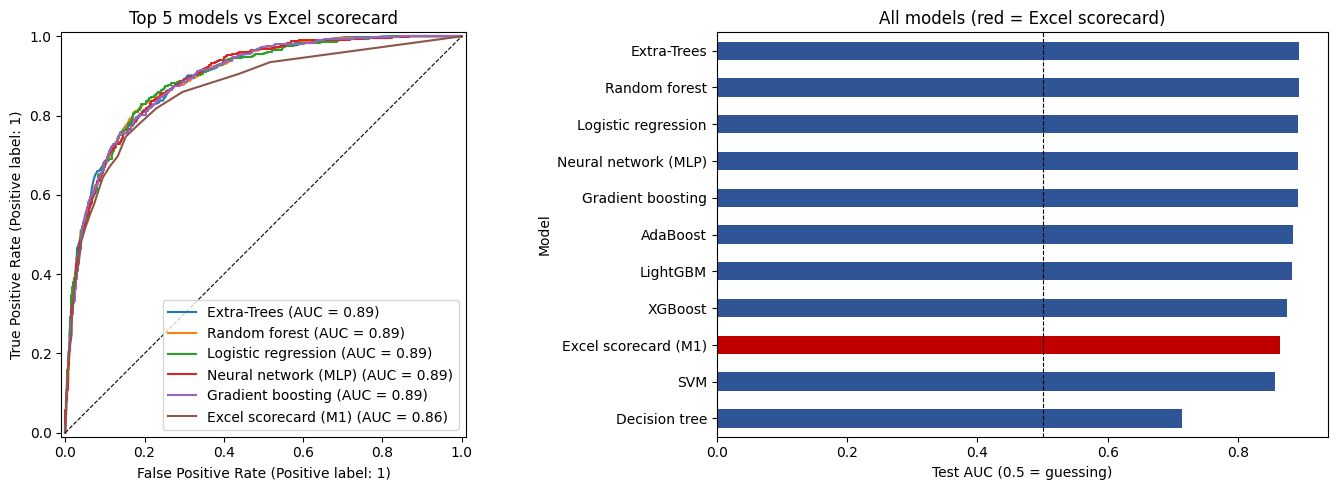

In [8]:
# Cell 8 — Charts: ROC curves and AUC ranking
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in comparison['Model'].head(5).tolist() + ['Excel scorecard (M1)']:
    RocCurveDisplay.from_predictions(y_test, probs[name], name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8); axes[0].set_title('Top 5 models vs Excel scorecard')
comparison.set_index('Model')['Test AUC'].sort_values().plot.barh(ax=axes[1],
    color=['#C00000' if m == 'Excel scorecard (M1)' else '#2F5597' for m in comparison.set_index('Model')['Test AUC'].sort_values().index])
axes[1].axvline(0.5, color='k', ls='--', lw=0.8); axes[1].set_xlabel('Test AUC (0.5 = guessing)')
axes[1].set_title('All models (red = Excel scorecard)')
plt.tight_layout(); plt.show()

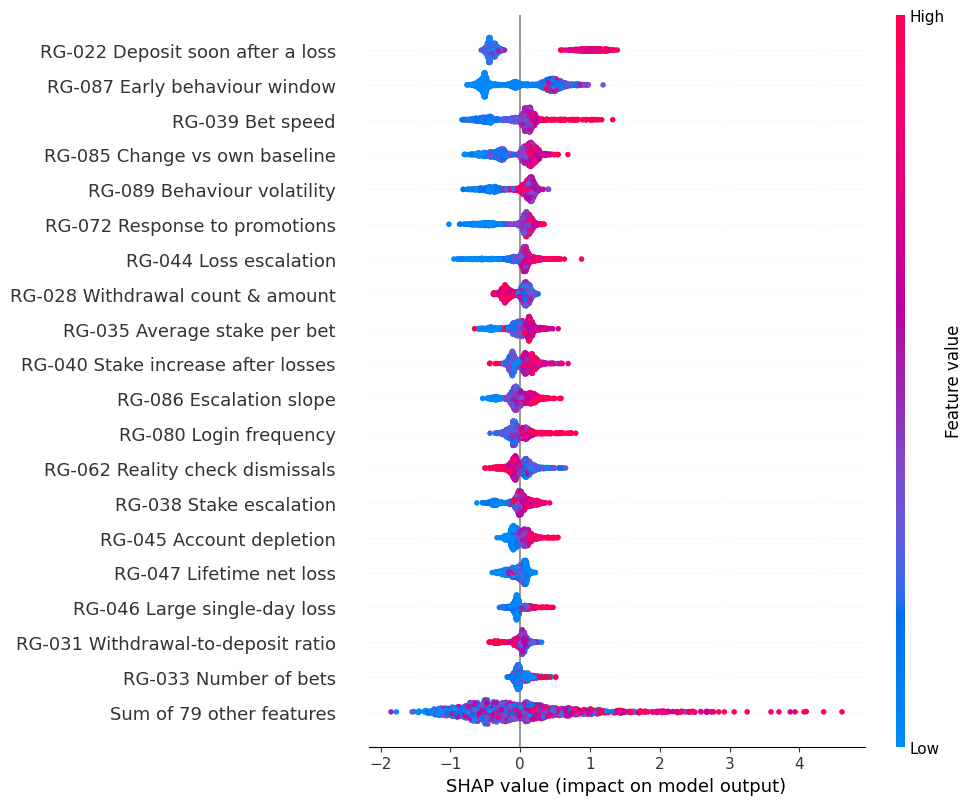

,RG ID,Data point,Category,mean |SHAP|,Direction,Share of total,Cumulative share
0,RG-022,Deposit soon after a loss,3. Deposits,0.5694,higher = riskier,0.1113,0.1113
1,RG-087,Early behaviour window,13. Change & trend,0.4426,higher = riskier,0.0865,0.1978
2,RG-039,Bet speed,5. Betting & staking,0.2295,higher = riskier,0.0449,0.2426
3,RG-085,Change vs own baseline,13. Change & trend,0.2171,higher = riskier,0.0424,0.2851
4,RG-089,Behaviour volatility,13. Change & trend,0.2005,higher = riskier,0.0392,0.3242
5,RG-072,Response to promotions,10. Bonuses & marketing,0.1797,higher = riskier,0.0351,0.3594
6,RG-044,Loss escalation,6. Losses & financial outcome,0.1414,higher = riskier,0.0276,0.3870
7,RG-028,Withdrawal count & amount,4. Withdrawals,0.1344,lower = riskier,0.0263,0.4133
8,RG-035,Average stake per bet,5. Betting & staking,0.1299,higher = riskier,0.0254,0.4387
9,RG-040,Stake increase after losses,5. Betting & staking,0.1268,higher = riskier,0.0248,0.4634


In [9]:
# Cell 9 — Which of the 89 data points matter? (SHAP on LightGBM)
gbm = fitted['LightGBM']
sample = X_test.sample(min(1500, len(X_test)), random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(gbm)
sv = explainer(sample)
vals = sv.values[:, :, 1] if sv.values.ndim == 3 else sv.values
shap.plots.beeswarm(shap.Explanation(vals, data=sample.values, feature_names=sample.columns.tolist()), max_display=20)

imp = pd.DataFrame({'column': sample.columns, 'mean |SHAP|': np.abs(vals).mean(axis=0)})
imp['RG ID'] = imp['column'].map(lambda c: f'RG-{rg_id(c):03d}')
imp['Data point'] = imp['column'].map(lambda c: META[rg_id(c)][0])
imp['Category'] = imp['column'].map(lambda c: META[rg_id(c)][1])
imp['Direction'] = [('higher = riskier' if np.corrcoef(sample[c], vals[:, k])[0, 1] > 0 else 'lower = riskier')
                    if sample[c].std() > 0 else '–' for k, c in enumerate(sample.columns)]
dp_imp = (imp.groupby(['RG ID', 'Data point', 'Category'], as_index=False)
             .agg({'mean |SHAP|': 'sum', 'Direction': 'first'})
             .sort_values('mean |SHAP|', ascending=False).reset_index(drop=True))
dp_imp['Share of total'] = dp_imp['mean |SHAP|'] / dp_imp['mean |SHAP|'].sum()
dp_imp['Cumulative share'] = dp_imp['Share of total'].cumsum()
display(dp_imp.head(25).round(4))

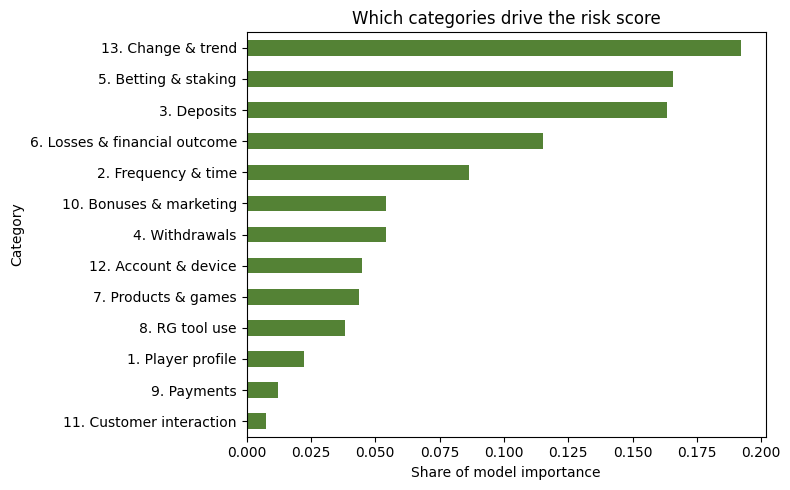

34 of 87 data points explain 80% of the model’s importance


In [10]:
# Cell 10 — Importance by category
cat_imp = dp_imp.groupby('Category')['Share of total'].sum().sort_values()
ax = cat_imp.plot.barh(figsize=(8, 5), color='#548235')
ax.set_xlabel('Share of model importance'); ax.set_title('Which categories drive the risk score')
plt.tight_layout(); plt.show()
n80 = int((dp_imp['Cumulative share'] < 0.8).sum()) + 1
print(f'{n80} of {len(dp_imp)} data points explain 80% of the model’s importance')

,Top data points,Columns,LightGBM test AUC
0,5,5,0.876
1,10,10,0.878
2,15,15,0.879
3,20,20,0.882
4,30,30,0.883
5,87,98,0.882


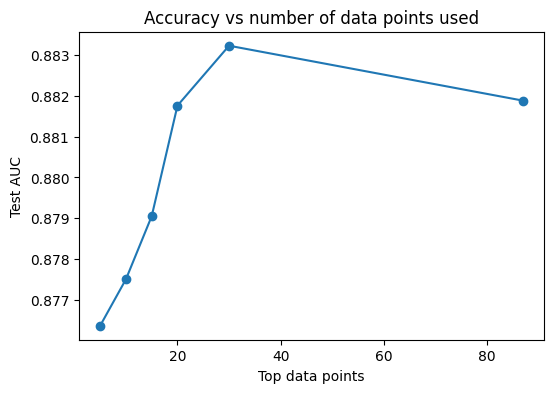

In [11]:
# Cell 11 — Do we need all 89? Retrain on the top N data points only
results = []
for top_n in [5, 10, 15, 20, 30, len(dp_imp)]:
    keep_ids = set(int(r[3:6]) for r in dp_imp['RG ID'].head(top_n))
    cols = [c for c in X.columns if rg_id(c) in keep_ids]
    m = lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1).fit(X_train[cols], y_train)
    results.append({'Top data points': top_n, 'Columns': len(cols),
                    'LightGBM test AUC': roc_auc_score(y_test, m.predict_proba(X_test[cols])[:, 1])})
fewer = pd.DataFrame(results); display(fewer.round(3))
fewer.plot(x='Top data points', y='LightGBM test AUC', marker='o', legend=False, figsize=(6, 4),
           title='Accuracy vs number of data points used'); plt.ylabel('Test AUC'); plt.show()

Model: Extra-Trees


,Flag top %,"Players to review (per 1,000)",Cases caught (sensitivity),Flags that are real cases (precision)
0,5%,50,0.182,0.893
1,10%,100,0.338,0.851
2,15%,150,0.492,0.811
3,20%,200,0.603,0.759
4,30%,300,0.763,0.640
5,40%,400,0.846,0.532
6,50%,500,0.913,0.462


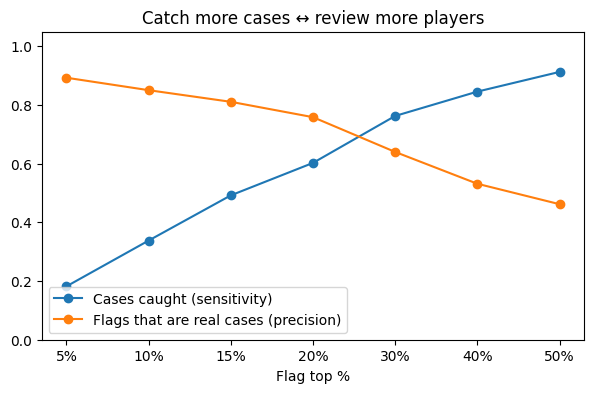

In [12]:
# Cell 12 — Review-capacity trade-off: how many players must the RG team review?
best = comparison.iloc[0]['Model']
p = probs[best]
rows = []
for share in [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]:
    cut = np.quantile(p, 1 - share)
    flag = (p >= cut).astype(int)
    rows.append({'Flag top %': f'{share:.0%}', 'Players to review (per 1,000)': int(share * 1000),
                 'Cases caught (sensitivity)': recall_score(y_test, flag),
                 'Flags that are real cases (precision)': precision_score(y_test, flag)})
tradeoff = pd.DataFrame(rows)
print('Model:', best); display(tradeoff.round(3))
ax = tradeoff.plot(x='Flag top %', y=['Cases caught (sensitivity)', 'Flags that are real cases (precision)'],
                   marker='o', figsize=(7, 4), title='Catch more cases ↔ review more players')
ax.set_ylim(0, 1.05); plt.show()

In [13]:
# Cell 13 — Suggested scorecard for the Excel (top 15 data points)
top = dp_imp.head(15).copy()
def suggested_threshold(row):
    col = COLS[int(row['RG ID'][3:]) - 1]
    if col not in X_train:                       # one-hot (text) data point
        return 'see category'
    q = 0.8 if row['Direction'] == 'higher = riskier' else 0.2
    return round(float(X_train[col].quantile(q)), 2)
top['Rule'] = np.where(top['Direction'] == 'higher = riskier', '>=', '<=')
top['Suggested threshold'] = top.apply(suggested_threshold, axis=1)
top['Suggested weight (1–3)'] = pd.cut(top['mean |SHAP|'], 3, labels=[1, 2, 3]).astype(int)
excel_weights = top[['RG ID', 'Data point', 'Category', 'Rule', 'Suggested threshold', 'Suggested weight (1–3)', 'Share of total']]
display(excel_weights.round(3))
print('Copy these into Model Settings (M1) in the Excel to make the scorecard evidence-based.')

,RG ID,Data point,Category,Rule,Suggested threshold,Suggested weight (1–3),Share of total
0,RG-022,Deposit soon after a loss,3. Deposits,>=,3.00,3,0.111
1,RG-087,Early behaviour window,13. Change & trend,>=,2552.00,3,0.087
2,RG-039,Bet speed,5. Betting & staking,>=,5.50,1,0.045
3,RG-085,Change vs own baseline,13. Change & trend,>=,42.00,1,0.042
4,RG-089,Behaviour volatility,13. Change & trend,>=,0.59,1,0.039
5,RG-072,Response to promotions,10. Bonuses & marketing,>=,0.32,1,0.035
6,RG-044,Loss escalation,6. Losses & financial outcome,>=,35.00,1,0.028
7,RG-028,Withdrawal count & amount,4. Withdrawals,<=,1.00,1,0.026
8,RG-035,Average stake per bet,5. Betting & staking,>=,2.20,1,0.025
9,RG-040,Stake increase after losses,5. Betting & staking,>=,1.25,1,0.025


Copy these into Model Settings (M1) in the Excel to make the scorecard evidence-based.


In [14]:
# Cell 14 — Export results
import os, shutil
os.makedirs('results', exist_ok=True)
comparison.to_csv('results/model_comparison.csv', index=False)
dp_imp.to_csv('results/data_point_importance.csv', index=False)
tradeoff.to_csv('results/review_capacity_tradeoff.csv', index=False)
fewer.to_csv('results/fewer_data_points.csv', index=False)
excel_weights.to_csv('results/suggested_excel_weights.csv', index=False)
shutil.make_archive('rg_universal_model_results', 'zip', 'results')
try:
    from google.colab import files; files.download('rg_universal_model_results.zip')
except ImportError:
    print('Saved rg_universal_model_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Caveats
- **Simulated data:** the patterns were written into the generator, so the models are partly rediscovering them. Real-data accuracy will be lower; published AUCs are roughly 0.6–0.84.
- **Near-perfect scores = check for leakage.** PGSI and past RG interaction outcomes are excluded for this reason.
- **The simulated outcome is not a real harm label.** Real labels (RG intervention, self-exclusion, PGSI, diagnosis) each have known weaknesses.
- **Real data needs approval first:** DPIA, anonymisation, and human review of every flag (GDPR Article 22).

In [15]:
players.to_csv('simulated_players_8000.csv', index=False)
from google.colab import files
files.download('simulated_players_8000.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>